# Case 2 trajectories and Poincaré sections

For four representative energies, the upper row shows the trajectory over the first 300 time units. The lower row shows 200 upward crossings of $y_1=y_{eq}$, projected onto $(x_1,p_{x1})$.

In [5]:
import matplotlib.pyplot as plt
import numpy as np

from initial_conditions import initial_conditions
from system import System, inverse_power_potential, kinetic

In [6]:
PARAMETERS = {
    "k": 1.0, "alpha": 1.0, "beta": 1.0,
    "C": 1.0, "Lx": 10.0, "Ly": 10.0,
}
MASSES = np.ones(2)
Y_EQUILIBRIUM = 3.6644771408428354
Q_CASE2 = np.asarray(initial_conditions["case2"][0], dtype=float)
VELOCITIES = np.geomspace(0.05, 3.0, 12)[[0, 3, 8, 11]]

seed_p = np.array([[0.0, VELOCITIES[0]], [0.0, -VELOCITIES[0]]])
system = System(
    Q_CASE2.copy(), seed_p, kinetic, inverse_power_potential,
    PARAMETERS, masses=MASSES,
)

In [7]:
POSITION_LABELS = np.array(["x1", "y1", "x2", "y2"])


def total_energy(q, p):
    return float(kinetic(p, MASSES) + inverse_power_potential(q, **PARAMETERS))


def choose_section(p0):
    velocity = np.asarray(p0, dtype=float) / MASSES[:, None]
    coordinate = int(np.argmax(np.abs(velocity.ravel())))
    return coordinate, float(np.sign(velocity.ravel()[coordinate]))


def independent_pair(q, p, section_coordinate):
    particle, section_axis = divmod(section_coordinate, 2)
    transverse_axis = 1 - section_axis
    return np.array([q[particle, transverse_axis], p[particle, transverse_axis]])


def projection_labels(section_coordinate):
    particle, section_axis = divmod(section_coordinate, 2)
    axis_name = "x" if 1 - section_axis == 0 else "y"
    return f"{axis_name}{particle + 1}", f"p{axis_name}{particle + 1}"


def collect_case(
    force, q0, p0, h, trajectory_steps, name, target_returns=200,
    section_coordinate=None, section_value=None,
):
    q = np.asarray(q0, dtype=float).copy()
    p = np.asarray(p0, dtype=float).copy()

    if section_coordinate is None:
        section_coordinate, direction = choose_section(p0)
    else:
        velocity = p / MASSES[:, None]
        direction = float(np.sign(velocity.ravel()[section_coordinate]))
    if section_value is None:
        section_value = q.ravel()[section_coordinate]

    initial_pair = independent_pair(q, p, section_coordinate)
    energy = total_energy(q, p)
    trajectory = [q.copy()]
    sample_stride = max(1, trajectory_steps // 2000)
    section = []
    max_energy_drift = 0.0

    for step in range(max(trajectory_steps, 20_000 * target_returns)):
        q_before = q.copy()
        p_before = p.copy()
        distance_before = direction * (q_before.ravel()[section_coordinate] - section_value)

        p_half = p_before + 0.5 * h * force(q_before)
        q = q_before + h * p_half / MASSES[:, None]
        p = p_half + 0.5 * h * force(q)

        if step < trajectory_steps and (
            (step + 1) % sample_stride == 0 or step + 1 == trajectory_steps
        ):
            trajectory.append(q.copy())

        distance_after = direction * (q.ravel()[section_coordinate] - section_value)
        if distance_before < 0.0 <= distance_after:
            fraction = -distance_before / (distance_after - distance_before)
            q_crossing = q_before + fraction * (q - q_before)
            p_crossing = p_before + fraction * (p - p_before)
            crossing_velocity = p_crossing.ravel()[section_coordinate] / MASSES.repeat(2)[section_coordinate]
            if direction * crossing_velocity > 0.0:
                section.append(independent_pair(q_crossing, p_crossing, section_coordinate))
                max_energy_drift = max(
                    max_energy_drift, abs(total_energy(q_crossing, p_crossing) - energy)
                )

        if step + 1 >= trajectory_steps and len(section) >= target_returns:
            break

    if len(section) < target_returns:
        raise RuntimeError(f"Only found {len(section)} of {target_returns} returns for {name}")

    return {
        "name": name, "h": h, "energy": energy,
        "trajectory": np.asarray(trajectory),
        "section": np.asarray(section[:target_returns]),
        "initial_pair": initial_pair, "section_coordinate": section_coordinate,
        "section_value": section_value, "direction": direction,
        "max_relative_energy_drift": max_energy_drift / abs(energy),
    }

In [8]:
results = []
for v in VELOCITIES:
    p0 = np.array([[0.0, v], [0.0, -v]])
    h = 0.005 * min(1.0, 1.0 / max(1.0, v))
    results.append(collect_case(
        system.force, Q_CASE2, p0, h, int(np.ceil(300.0 / h)), f"v={v:.6g}",
        section_coordinate=1, section_value=Y_EQUILIBRIUM,
    ))

for result in results:
    print(
        f"{result['name']}, E={result['energy']:.6f}, "
        f"returns={len(result['section'])}, "
        f"max dE/E={result['max_relative_energy_drift']:.2e}"
    )

v=0.05, E=2.007344, returns=200, max dE/E=1.54e-08
v=0.152729, E=2.028170, returns=200, max dE/E=2.64e-08
v=0.982134, E=2.969432, returns=200, max dE/E=1.01e-06
v=3, E=11.004844, returns=200, max dE/E=6.65e-08


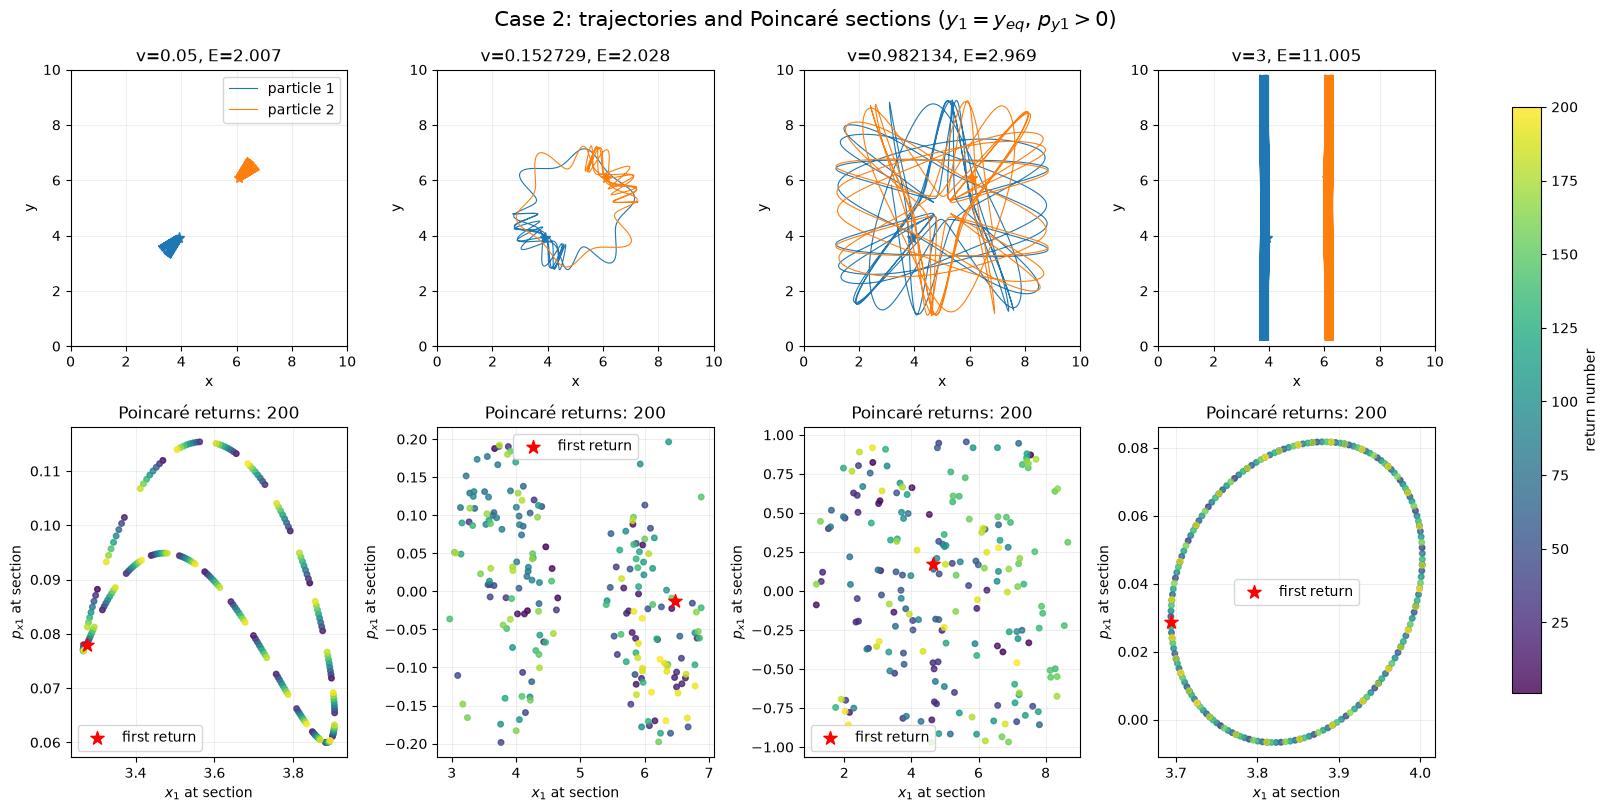

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
return_number = np.arange(1, 201)

for column, result in enumerate(results):
    trajectory_axis = axes[0, column]
    section_axis = axes[1, column]

    for particle in range(2):
        q = result["trajectory"][:, particle]
        trajectory_axis.plot(q[:, 0], q[:, 1], linewidth=0.8, label=f"particle {particle + 1}")
        trajectory_axis.plot(
            Q_CASE2[particle, 0], Q_CASE2[particle, 1],
            marker="*", color=f"C{particle}", markersize=8,
        )

    trajectory_axis.set(
        xlim=(0, 10), ylim=(0, 10), aspect="equal",
        xlabel="x", ylabel="y",
        title=f"{result['name']}, E={result['energy']:.3f}",
    )
    if column == 0:
        trajectory_axis.legend()

    points = result["section"]
    scatter = section_axis.scatter(
        points[:, 0], points[:, 1], c=return_number,
        cmap="viridis", s=16, alpha=0.8,
    )
    section_axis.scatter(
        *points[0], marker="*", s=100, color="red", label="first return",
    )
    section_axis.set(
        xlabel=r"$x_1$ at section", ylabel=r"$p_{x1}$ at section",
        title=f"Poincaré returns: {len(points)}",
    )
    section_axis.legend()

    trajectory_axis.grid(alpha=0.2)
    section_axis.grid(alpha=0.2)

fig.colorbar(scatter, ax=axes.ravel().tolist(), label="return number", shrink=0.82)
fig.suptitle(r"Case 2: trajectories and Poincaré sections ($y_1=y_{eq}$, $p_{y1}>0$)", fontsize=15)
fig.savefig("case2_energy_trajectory_sections.png", dpi=180)
plt.show()

# Report 1 cases: trajectories and Poincaré sections

The upper row reproduces the five trajectories from `report01`. The lower row shows 200 oriented returns using an independent canonical projection for each section.

In [10]:
report01_results = [
    collect_case(system.force, q0, p0, h, 100_000, name)
    for name, (q0, p0, h) in initial_conditions.items()
]

In [11]:
for result in report01_results:
    print(
        f"{result['name']}: {len(result['section'])} returns, "
        f"max dE/E={result['max_relative_energy_drift']:.2e}"
    )

case1: 200 returns, max dE/E=1.25e-12
case2: 200 returns, max dE/E=5.99e-08
case3: 200 returns, max dE/E=9.70e-09
case4: 200 returns, max dE/E=1.81e-09
case5: 200 returns, max dE/E=8.92e-09


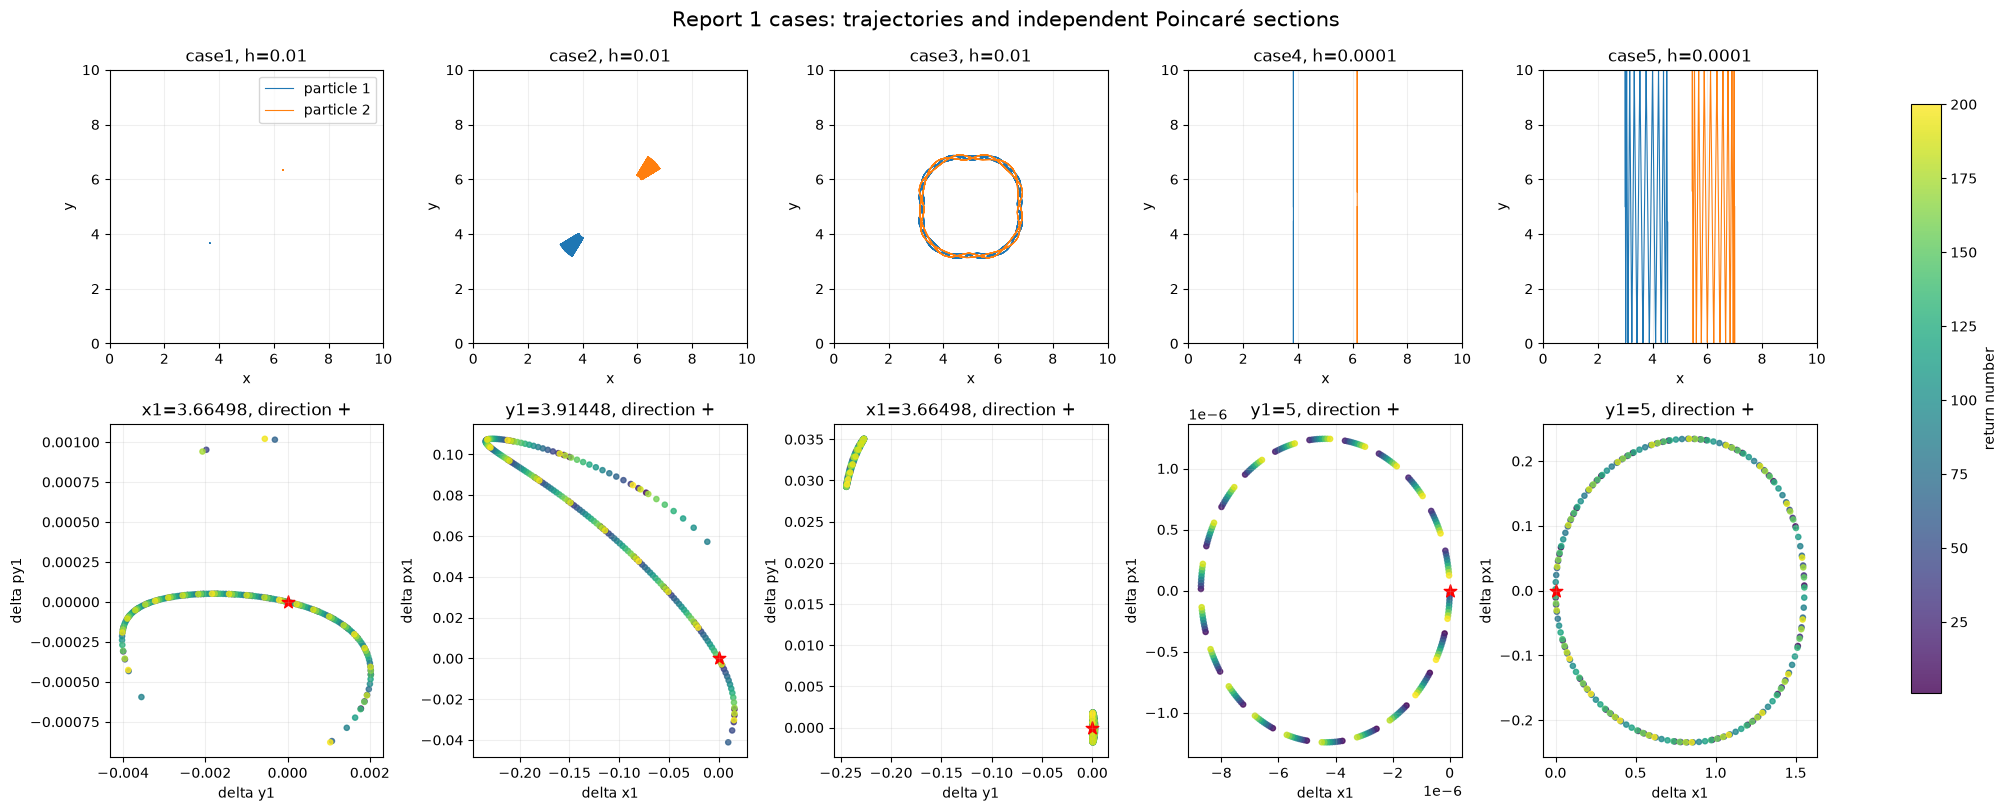

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)

for column, result in enumerate(report01_results):
    trajectory_axis = axes[0, column]
    section_axis = axes[1, column]

    for particle in range(2):
        q = result["trajectory"][:, particle]
        trajectory_axis.plot(q[:, 0], q[:, 1], linewidth=0.8, label=f"particle {particle + 1}")
    trajectory_axis.set(
        xlim=(0, 10), ylim=(0, 10), aspect="equal", xlabel="x", ylabel="y",
        title=f"{result['name']}, h={result['h']:g}",
    )
    if column == 0:
        trajectory_axis.legend()

    delta = result["section"] - result["initial_pair"]
    labels = projection_labels(result["section_coordinate"])
    scatter = section_axis.scatter(
        delta[:, 0], delta[:, 1], c=np.arange(1, len(delta) + 1),
        cmap="viridis", s=14, alpha=0.8,
    )
    section_axis.scatter(0.0, 0.0, marker="*", s=90, color="red")
    orientation = "+" if result["direction"] > 0 else "-"
    section_name = POSITION_LABELS[result["section_coordinate"]]
    section_axis.set(
        xlabel=f"delta {labels[0]}", ylabel=f"delta {labels[1]}",
        title=f"{section_name}={result['section_value']:.6g}, direction {orientation}",
    )
    trajectory_axis.grid(alpha=0.2)
    section_axis.grid(alpha=0.2)

fig.colorbar(scatter, ax=axes.ravel().tolist(), label="return number", shrink=0.82)
fig.suptitle("Report 1 cases: trajectories and independent Poincaré sections", fontsize=15)
fig.savefig("report01_cases_trajectory_sections.png", dpi=180)
plt.show()